# Plots as diagnostic instruments

The original visual grammar stays simple: gray observations, blue prediction crosses, and a visible forecast origin. A matrix lets us see stochastic variation directly.

**Development notebook.** Expand the library cells to edit the implementation. Examples below use local data and CPU. [Build workflow](README.md#develop-the-package-here).

In [1]:
#| default_exp plotting

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

%matplotlib inline
plt.style.use('default')
plt.rcParams.update({'figure.figsize': (12, 4), 'figure.dpi': 110,
    'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': False, 'legend.frameon': False, 'axes.titlelocation': 'left'})

## Build `plotting`

### Imports and configuration

In [3]:
#| export plotting
from __future__ import annotations
from timegym._internal import positive_int

import textwrap

import numpy as np
import pandas as pd

from timegym import metrics
from timegym.scenarios import scenario_label


_BLUE = "blue"
_GRAY = "gray"
_STYLE = {
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.grid": False, "font.size": 10, "axes.titlesize": 10,
    "axes.titlelocation": "left", "legend.fontsize": 8,
    "legend.frameon": True, "figure.dpi": 110,
}

### _pyplot

In [4]:
#| export plotting
def _pyplot():
    import matplotlib.pyplot as plt

    return plt

### _groups

In [5]:
#| export plotting
def _groups(run):
    if not run.cases:
        raise ValueError("Cannot plot an empty ForecastRun")
    groups = {}
    for entry in run.cases:
        groups.setdefault(entry.scenario_index, []).append(entry)
    return groups

### _time_coordinates — Return coordinates and a midpoint without relying on pandas plot state.

In [6]:
#| export plotting
def _time_coordinates(context_index, future_index, ax):
    """Return coordinates and a midpoint without relying on pandas plot state."""
    indexes = (context_index, future_index)
    if all(isinstance(index, (pd.DatetimeIndex, pd.PeriodIndex)) for index in indexes):
        import matplotlib.dates as mdates

        converted = [index.to_timestamp() if isinstance(index, pd.PeriodIndex) else index for index in indexes]
        coordinates = [mdates.date2num(index.to_pydatetime()) for index in converted]
        timezone = getattr(converted[0], "tz", None)
        locator = mdates.AutoDateLocator(minticks=3, maxticks=6, tz=timezone)
        ax.xaxis.set_major_locator(locator)
        ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator, tz=timezone))
        label = "Time"
    elif all(isinstance(index, pd.TimedeltaIndex) for index in indexes):
        coordinates = [index.total_seconds().to_numpy() for index in indexes]
        label = "Elapsed time (seconds)"
    elif all(pd.api.types.is_numeric_dtype(index.dtype) for index in indexes):
        coordinates = [index.to_numpy(dtype=float) for index in indexes]
        label = "Time index"
    else:
        # A custom model may use ordered nonnumeric labels. Show those labels
        # explicitly on an ordinal axis rather than pretending they are dates.
        labels = list(context_index) + list(future_index)
        coordinates = [np.arange(len(context_index)), np.arange(len(context_index), len(labels))]
        locations = np.unique(np.linspace(0, len(labels) - 1, min(6, len(labels)), dtype=int))
        ax.set_xticks(locations, [str(labels[position]) for position in locations])
        label = "Index label (equally spaced)"
    context_x, future_x = coordinates
    cutoff = context_x[-1] + (future_x[0] - context_x[-1]) / 2
    return context_x, future_x, cutoff, label

### _annotate

In [7]:
#| export plotting
def _annotate(ax, messages):
    if messages:
        message = "\n".join(textwrap.fill(str(item), width=66) for item in messages)
        ax.text(0.02, 0.02, message, transform=ax.transAxes, va="bottom", ha="left",
                fontsize=8, color="#8B0000", bbox={"facecolor": "white", "alpha": 0.92, "edgecolor": "none"})

### _diagnostic_problems

In [8]:
#| export plotting
def _diagnostic_problems(entry):
    return [f"{diagnostic.status} · {diagnostic.name}: {diagnostic.message}"
            for diagnostic in entry.result.diagnostics if diagnostic.failed]

### _valid_reference

In [9]:
#| export plotting
def _valid_reference(case):
    reference = case.reference
    shape = (len(case.task.future_index), len(case.task.target_names))
    return (reference is not None and reference.index.equals(case.task.future_index)
            and tuple(reference.target_names) == case.task.target_names
            and np.asarray(reference.mean).shape == shape
            and np.isfinite(reference.mean).all())

### _draw_case

In [10]:
#| export plotting
def _draw_case(ax, entry, target, *, show_quantiles):
    case = entry.case
    task = case.task
    messages = []
    if target not in task.target_names:
        ax.set_axis_off()
        ax.text(0.5, 0.5, f"Target {target!r} is absent in this case", transform=ax.transAxes, ha="center")
        return
    dimension = task.target_names.index(target)
    context_x, future_x, cutoff, xlabel = _time_coordinates(task.context.index, task.future_index, ax)
    ax.plot(context_x, task.context.iloc[:, dimension].to_numpy(), color=_GRAY,
            marker=".", markersize=2.5, linestyle="None", label="Observed context")
    observed_valid = (case.observed.index.equals(task.future_index)
                      and tuple(case.observed.columns) == task.target_names
                      and case.observed.shape == (len(future_x), len(task.target_names)))
    if observed_valid:
        observed = case.observed.iloc[:, dimension].to_numpy(dtype=float)
        observed_valid = bool(np.isfinite(observed).all())
    if observed_valid:
        ax.plot(future_x, observed, color=_GRAY, marker=".", markersize=3,
                linestyle="None", label="Held-out observations")
    else:
        messages.append("Held-out observations violate the evaluation contract; not plotted.")

    reference_valid = _valid_reference(case)
    if reference_valid:
        ax.plot(future_x, case.reference.mean[:, dimension], color=_GRAY,
                linewidth=1, label=("Conditional mean (approx. filter)" if
                           getattr(case.reference, "sampler_kind", None) == "approximate_conditional"
                           else "Known conditional mean"))
    elif case.reference is not None:
        messages.append("Conditional reference is misaligned or nonfinite; not plotted.")

    forecast = entry.forecast
    score_text = []
    if forecast is None:
        messages.append("No forecast: model execution failed.")
    else:
        try:
            violations = forecast.validate(task)
        except Exception as exc:
            violations = [{"code": "validation_error", "message": f"{type(exc).__name__}: {exc}"}]
        if violations:
            messages.append("Invalid forecast; predictions not plotted: " + "; ".join(
                f"{violation['code']}: {violation['message']}" for violation in violations))
        else:
            if forecast.point is not None:
                point = np.asarray(forecast.point, dtype=float)[:, dimension]
                ax.plot(future_x, point, color=_BLUE, marker="x", markersize=3.5,
                        markeredgewidth=0.8, linestyle="None", label="Predictive mean")
                if observed_valid:
                    score_text.append(f"observed MSE={metrics.mse(observed, point):.3g}")
                if reference_valid:
                    score_text.append(f"mean-reference MSE={metrics.mean_reference_mse(case.reference.mean[:, dimension], point):.3g}")
            else:
                messages.append("No explicit predictive mean supplied; no point predictions plotted.")
            if show_quantiles:
                if forecast.quantiles is not None and len(forecast.levels) >= 2:
                    quantiles = np.asarray(forecast.quantiles, dtype=float)
                    coverage = 100 * (float(forecast.levels[-1]) - float(forecast.levels[0]))
                    ax.fill_between(future_x, quantiles[:, dimension, 0], quantiles[:, dimension, -1],
                                    color=_BLUE, alpha=0.1, label=f"{coverage:g}% marginal interval")
                else:
                    messages.append("Marginal interval unavailable: two explicit quantile levels are required.")

    problems = _diagnostic_problems(entry)
    # Contract failures already have the more specific validation annotation.
    other_problems = [problem for problem in problems if "contract_" not in problem]
    messages.extend(other_problems)
    ax.axvline(cutoff, color=_BLUE, linewidth=1.2, linestyle="--", label="Forecast origin")
    ax.set_xlim(context_x[0], future_x[-1])
    ax.set_xlabel(xlabel)
    ax.set_ylabel(str(target))
    label = scenario_label(entry.result.scenario, case.manifest.get("parameters"), target_index=dimension)
    title = f"{entry.scenario_index + 1}. {label} · {target} · seed={entry.result.seed}"
    if len(title) > 82:
        title = textwrap.fill(title, width=70, break_long_words=False)
    if score_text:
        title += "\n" + "; ".join(score_text)
    ax.set_title(title, loc="left")
    ax.legend(loc="upper left")
    _annotate(ax, messages)

### plot_forecasts — Plot retained forecasts as scenario/target rows and seed columns.

In [11]:
#| export plotting
def plot_forecasts(run, *, show_quantiles=False, figsize=None):
    """Plot retained forecasts as scenario/target rows and seed columns.

    Every model point is an unconnected blue cross, including dense forecast
    horizons. Reference curves are conditional means for the future only.
    Facets have separate target axes and display target-specific MSEs. Bands,
    when requested, are marginal intervals, never simultaneous path regions.
    """
    if not isinstance(show_quantiles, bool):
        raise ValueError("show_quantiles must be a boolean")
    groups = _groups(run)
    columns = sorted({entry.seed_index for entry in run.cases})
    rows = []
    lookup = {}
    for scenario_index, entries in groups.items():
        targets = list(dict.fromkeys(target for entry in entries for target in entry.case.task.target_names))
        rows.extend((scenario_index, target) for target in targets)
        for entry in entries:
            key = (scenario_index, entry.seed_index)
            if key in lookup:
                raise ValueError("ForecastRun contains duplicate scenario/seed positions")
            lookup[key] = entry
    plt = _pyplot()
    with plt.rc_context(_STYLE):
        fig, axes = plt.subplots(len(rows), len(columns), squeeze=False,
                                 figsize=figsize or (6 * len(columns), 3.3 * len(rows)), layout="constrained")
        for row_index, (scenario_index, target) in enumerate(rows):
            for column_index, seed_index in enumerate(columns):
                ax = axes[row_index, column_index]
                entry = lookup.get((scenario_index, seed_index))
                if entry is None:
                    ax.set_axis_off()
                    ax.text(0.5, 0.5, "No evaluated case at this position", transform=ax.transAxes, ha="center")
                else:
                    _draw_case(ax, entry, target, show_quantiles=show_quantiles)
        return fig

### plot_errors — Show distributions of retained whole-case metrics, one row per scenario.

In [12]:
#| export plotting
def plot_errors(run, metric="mean_reference_mse", *, bins=None, missing="raise", figsize=None):
    """Show distributions of retained whole-case metrics, one row per scenario.

    These are distributions over evaluated cases, not over predictive sample
    draws or dependent coordinates. Scenario positions remain distinct even
    when their kind strings match. Missing scores are never silently dropped.
    """
    groups = _groups(run)
    if not isinstance(metric, str) or not metric:
        raise ValueError("metric must be a nonempty metric name")
    if missing not in {"raise", "annotate"}:
        raise ValueError("missing must be 'raise' or 'annotate'")
    if bins is not None:
        bins = positive_int(bins, "bins")
    values_by_group = {}
    missing_by_group = {}
    for scenario_index, entries in groups.items():
        values, unavailable = [], []
        for entry in entries:
            value = entry.result.metrics.get(metric)
            if isinstance(value, (int, float, np.integer, np.floating)) and np.isfinite(value):
                values.append(float(value))
            else:
                unavailable.append(entry)
        values_by_group[scenario_index], missing_by_group[scenario_index] = values, unavailable
    unavailable = [entry for entries in missing_by_group.values() for entry in entries]
    if unavailable and missing == "raise":
        identities = ", ".join(f"scenario #{entry.scenario_index + 1} seed={entry.result.seed}" for entry in unavailable)
        raise ValueError(f"Metric {metric!r} is missing or nonfinite for {len(unavailable)} case(s): {identities}. "
                         "Use missing='annotate' to display these omissions explicitly.")

    plt = _pyplot()
    with plt.rc_context(_STYLE):
        fig, axes = plt.subplots(len(groups), 1, squeeze=False,
                                 figsize=figsize or (10, 3 * len(groups)), layout="constrained")
        for ax, (scenario_index, entries) in zip(axes[:, 0], groups.items()):
            values, missing_entries = values_by_group[scenario_index], missing_by_group[scenario_index]
            if values:
                bin_count = bins if bins is not None else max(1, min(20, int(np.ceil(np.sqrt(len(values))))))
                ax.hist(values, bins=bin_count, color=_BLUE, alpha=0.55, edgecolor="white")
            label = ("Mean-reference MSE" if metric == "mean_reference_mse" else
                     "Observed-future MSE" if metric == "mse" else metric)
            ax.set_xlabel(f"{label} (one whole-case score)")
            ax.set_ylabel("Evaluated cases")
            process = scenario_label(entries[0].result.scenario, entries[0].case.manifest.get("parameters"))
            ax.set_title(f"{scenario_index + 1}. {process} · "
                         f"{len(values)} scored / {len(entries)} evaluated cases", loc="left")
            if missing_entries:
                messages = [f"{len(missing_entries)} case(s) have no finite {metric!r}; they are not in the histogram."]
                for entry in missing_entries:
                    problem = _diagnostic_problems(entry)
                    messages.append(f"seed={entry.result.seed}: {problem[0] if problem else 'metric unavailable'}")
                _annotate(ax, messages)
        return fig

## The original matrix, extended to multiple targets

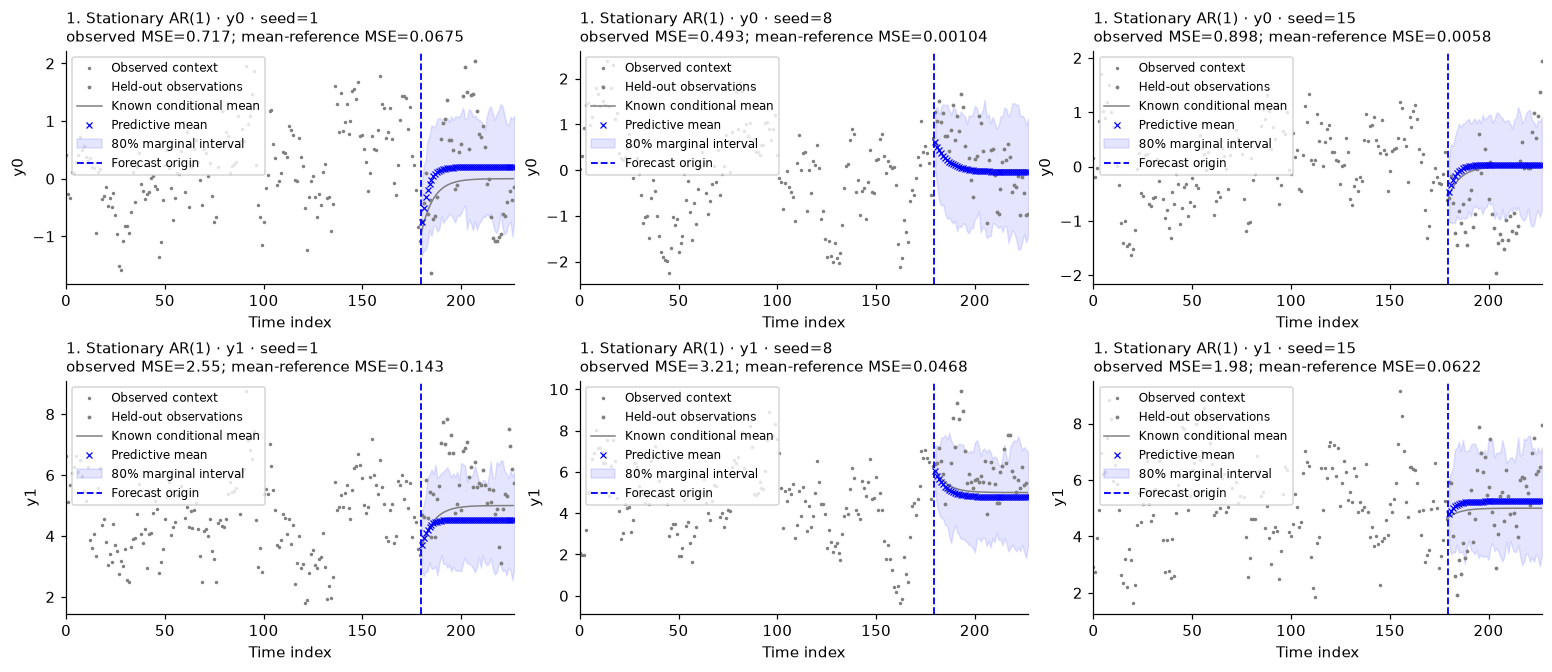

In [13]:
from timegym import Pipeline, Scenario, GaussianAR1Forecaster
case = Scenario('ar1', context_length=180, horizon=48, n_targets=2,
                parameters={'mean': [0., 5.], 'sigma': [.5, 1.], 'phi': .85, 'correlation': .7})
run = Pipeline(GaussianAR1Forecaster(n_samples=96, seed=12)).run([case], seeds=[1, 8, 15])
plot_forecasts(run, show_quantiles=True, figsize=(14, 6));
plt.show()

Each target gets its own row and units; each seeded realization gets a column. Dots and crosses stay discrete. Shading shows marginal intervals, not simultaneous coverage of the entire trajectory.

## Change one thing

Try one parameter or implementation change, rerun the relevant example, and inspect the figure or assertion. Save before exporting. The package tests provide broader regression coverage; the experiment here is intentionally small.